<a href="https://colab.research.google.com/github/roberthsu2003/machine_learning/blob/main/%E5%90%8D%E8%A9%9E%E8%A7%A3%E9%87%8B/07_%E5%B8%B8%E8%A6%8B%E7%AE%97%E6%B3%95/README.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 07. 常見演算法 (Common ML Algorithms: Non-Linear Boundaries)

本章聚焦於四大經典非線性演算法：
1. **K-近鄰 (K-NN)**：幾何距離投票。
2. **決策樹 (Decision Tree)**：正交軸向階層切割。
3. **支援向量機 (SVM)**：最大間隔與高維核技巧。
4. **樸素貝氏 (Naive Bayes)**：機率生成與條件獨立推斷。

本範例讀取繁體中文「雙月牙非線性資料集」，並使用 Matplotlib 繪製四者的**非線性決策邊界 (Decision Boundaries)**！

In [1]:
%%capture
%pip install mplfonts seaborn scikit-learn pandas numpy matplotlib


In [2]:
# --- 設定 Matplotlib / Seaborn 中文字型支援（Mac / Windows / Colab 通用）---
import glob
import os
import mplfonts
from matplotlib import font_manager
import matplotlib.pyplot as plt
import seaborn as sns
from mplfonts import use_font

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    font_manager.fontManager.addfont(f)
use_font("Noto Sans CJK SC")
plt.rcParams['axes.unicode_minus'] = False
print("繁體中文字型已成功載入！")


繁體中文字型已成功載入！


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# 讀取雙月牙資料集
df = pd.read_csv('雙月牙非線性資料集.csv')
X = df[['特徵一', '特徵二']].values
y = (df['類別標籤'] == '類別乙').astype(int).values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

models = {
    '1. K-近鄰 (KNN)': KNeighborsClassifier(n_neighbors=5),
    '2. 決策樹 (Decision Tree)': DecisionTreeClassifier(max_depth=4, random_state=42),
    '3. 支援向量機 (SVM 高斯核)': SVC(kernel='rbf', C=1.0, random_state=42),
    '4. 樸素貝氏 (GaussianNB)': GaussianNB()
}

print("=== 四大演算法在非線性資料的測試準確率 ===")
for name, model in models.items():
    model.fit(X_train, y_train)
    acc = model.score(X_test, y_test)
    print(f"{name:25s} ➔ 測試準確率: {acc:.1%}")


=== 四大演算法在非線性資料的測試準確率 ===
1. K-近鄰 (KNN)             ➔ 測試準確率: 95.0%
2. 決策樹 (Decision Tree)    ➔ 測試準確率: 95.0%
3. 支援向量機 (SVM 高斯核)        ➔ 測試準確率: 96.7%
4. 樸素貝氏 (GaussianNB)      ➔ 測試準確率: 83.3%


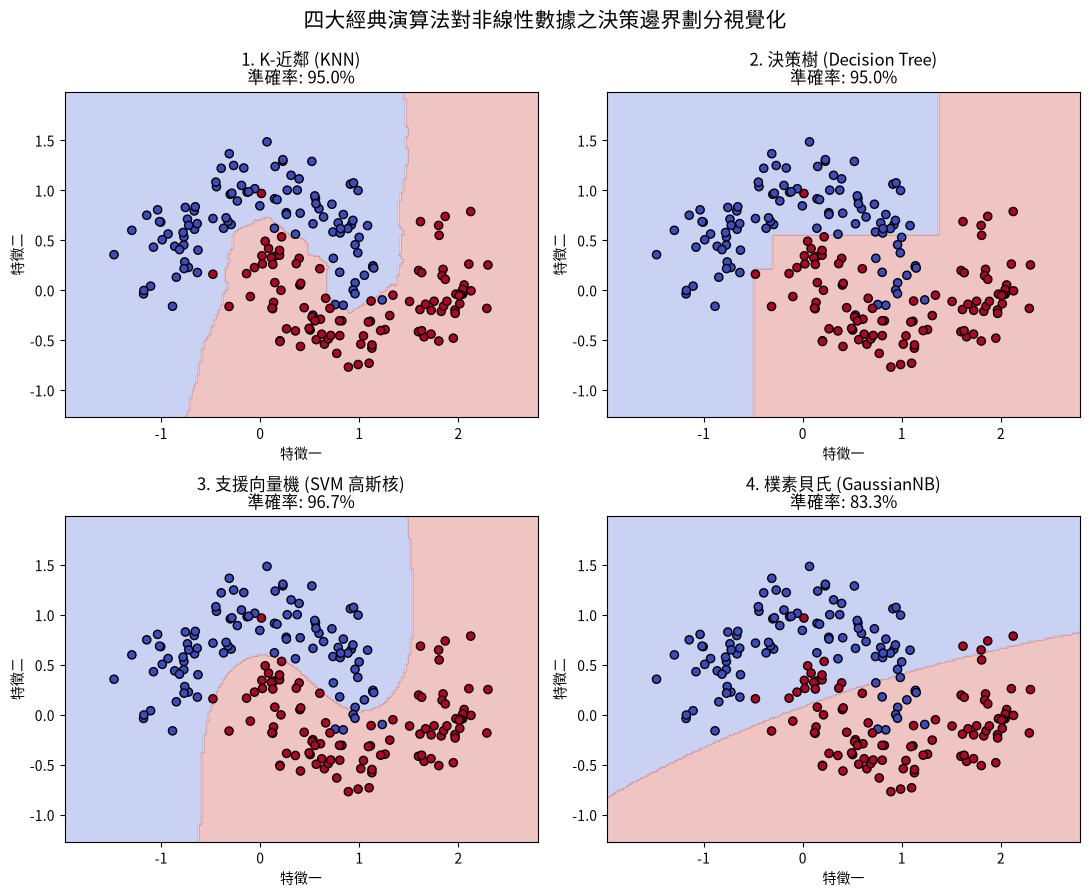

💡 觀念總結：四大算法各自透過局部投票、正交分割、高維投影或機率曲線，成功突破線性超平面的束縛！


In [4]:
# 繪製四大演算法的二維決策邊界圖
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
axes = axes.ravel()

for idx, (name, model) in enumerate(models.items()):
    ax = axes[idx]
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    scatter = ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolor='k', s=35)
    ax.set_title(f"{name}\n準確率: {model.score(X_test, y_test):.1%}", fontsize=12)
    ax.set_xlabel('特徵一', fontsize=10)
    ax.set_ylabel('特徵二', fontsize=10)

plt.suptitle('四大經典演算法對非線性數據之決策邊界劃分視覺化', fontsize=15, y=0.99)
plt.tight_layout()
plt.show()

print("💡 觀念總結：四大算法各自透過局部投票、正交分割、高維投影或機率曲線，成功突破線性超平面的束縛！")
